# Laboratorium 2 - wieloręcy bandyci

## Przygotowanie

 * [opcjonalnie] Utwórz wirtualne środowisko
 `python3 -m venv ./recsyslab2`
 * zainstaluj potrzebne biblioteki:
 `pip3 install matplotlib`
 * upewnij się, że plik `bandit_framework.py` znajduje się w tym samym katalogu

## Część 1. - framework i naiwni bandyci

### Framework

Plik `bandit_framework.py` zawiera:
 * `Arm` - ramię o zadanym prawdopodobieństwie kliknięcia `click_probability`. Metoda `pull()` zwraca 1 (kliknięcie) lub 0. Bandyci **nie znają** tego prawdopodobieństwa - muszą się go nauczyć.
 * `Bandit` - klasa bazowa wszystkich algorytmów. Kontrakt:
   * `recommend(size)` zwraca listę **dokładnie** `size` **różnych** identyfikatorów ramion,
   * `feedback(arm_id, reward)` jest wywoływana po każdej rekomendacji **osobno dla każdego zarekomendowanego ramienia**, z nagrodą 0 lub 1.
 * `Runner` - przeprowadza symulację. W każdej epoce prosi bandytę o rekomendację, sprawdza jej poprawność (rozmiar, duplikaty, nieznane ramiona), pociąga każde zarekomendowane ramię i przekazuje bandycie wynik przez `feedback()`. Metoda `simulate()` zwraca listę obiektów `SimulationResult` (po jednym na bandytę) z nagrodą (reward) i regretem w każdej epoce.

Bandyci uczą się w trakcie symulacji, więc przed każdą nową symulacją trzeba ich utworzyć od nowa.

### Metryka - regret

Liczba kliknięć jest losowa i nie mówi wprost, jak daleko jesteśmy od ideału. Dlatego głównie patrzymy na **regret** - różnicę między oczekiwaną nagrodą najlepszej możliwej rekomendacji a oczekiwaną nagrodą rekomendacji bandyty:

$$\text{regret}_t = \sum_{a \in A^*} p_a - \sum_{a \in A_t} p_a$$

gdzie $A^*$ to zbiór ramion o najwyższym CTR, $A_t$ - rekomendacja bandyty w epoce $t$, a $p_a$ - prawdziwe prawdopodobieństwo kliknięcia ramienia $a$. Regret liczymy z prawdziwych prawdopodobieństw, więc nie zależy od szczęścia w losowaniu kliknięć.

Na wykresach pokazujemy **skumulowany regret** $\sum_{t} \text{regret}_t$:
 * jeśli rośnie liniowo - bandyta się nie uczy (albo wciąż płaci za eksplorację),
 * jeśli się wypłaszcza - bandyta znalazł najlepsze ramiona.

In [1]:
# importujemy wszystkie potrzebne pakiety

from copy import copy
from dataclasses import dataclass
from math import inf, log, sqrt
from random import betavariate, choice, random, sample, seed, shuffle, uniform
from typing import Dict, List, NamedTuple, Tuple
from bandit_framework import *  # pakiet ze srodowiskiem testowym

In [2]:
# inicjalizujemy parametry testu

seed(42)  # dla powtarzalnosci wynikow
epochs = 200
recommendation_size = 10

In [3]:
# inicjalizujemy ramiona bandytow
# ramiona dzielimy na grupy; CTR ramienia losujemy z przedzialu przypisanego do jego grupy
# nazwy ramion (np. top_3) sluza tylko nam do analizy wynikow - bandyci nie powinni z nich korzystac

class ArmTier(NamedTuple):
    name: str
    count: int
    ctr_range: Tuple[float, float]


def create_arms(tiers: List[ArmTier]) -> Dict[str, Arm]:
    all_arms = [Arm(f'{tier.name}_{i}', uniform(*tier.ctr_range)) for tier in tiers for i in range(tier.count)]
    shuffle(all_arms)
    return {arm.arm_id: arm for arm in all_arms}


tiers = [
    ArmTier('top', 5, (0.5, 0.7)),
    ArmTier('good', 15, (0.3, 0.5)),
    ArmTier('average', 50, (0.1, 0.3)),
    ArmTier('poor', 130, (0.0, 0.1)),
]
arms = create_arms(tiers)
arm_ids = list(arms.keys())

In [4]:
best_expected_reward = sum(sorted([arm.click_probability for arm in arms.values()], reverse=True)[:recommendation_size])
print(f'Number of arms: {len(arms)}')
print(f'Expected highest reward per epoch: {best_expected_reward:.2f}')

Number of arms: 200
Expected highest reward per epoch: 5.10


In [5]:
# pierwszy bandyta - wybiera losowe ramiona

class Random(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str]):
        super().__init__(bandit_id, arm_ids)

    def recommend(self, size: int) -> List[str]:
        return sample(self.arm_ids, size)

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [6]:
# drugi bandyta (wyrocznia) korzysta z wiedzy, do ktorej przecietny bandyta nie ma dostepu

class Oracle(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], arms: Dict[str, Arm]):
        super().__init__(bandit_id, arm_ids)
        self.ranking = sorted(arm_ids, key=lambda arm_id: arms[arm_id].click_probability, reverse=True)

    def recommend(self, size: int) -> List[str]:
        return self.ranking[:size]

    def feedback(self, arm_id: str, reward: int) -> None:
        pass

In [7]:
# tworzymy liste bandytow do przetestowania

bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms)
]

In [8]:
# uruchamiamy test

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle

bandit                 total reward   total regret
oracle                         1022            0.0
random                          250          775.9


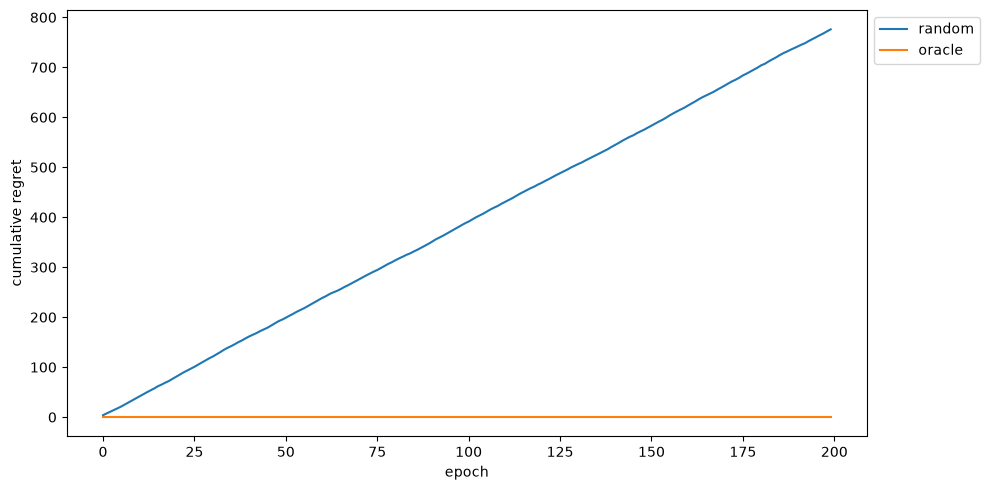

In [9]:
# skumulowany regret

runner.plot_results(results, mode='regret')

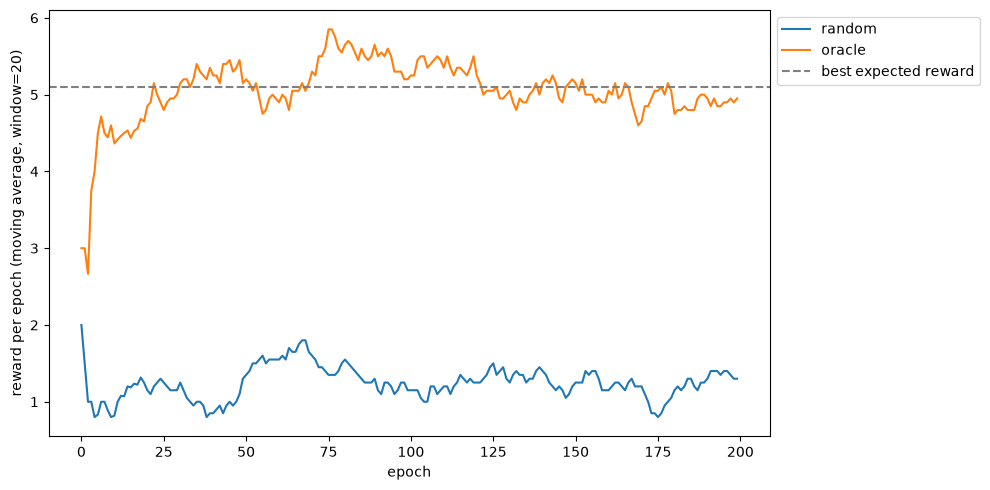

In [10]:
# reward (liczba klikniec) per epoka

runner.plot_results(results, mode='reward')

## Część 2. - ε-greedy

In [11]:
import numpy as np

In [12]:
# statystyki, ktore bandyta zbiera o jednym ramieniu - uzyjemy ich we wszystkich bandytach

@dataclass
class ArmStats:
    trials: int = 0     # ile razy ramie bylo rekomendowane
    successes: int = 0  # ile razy zostalo klikniete

    @property
    def failures(self) -> int:
        return self.trials - self.successes

    @property
    def mean(self) -> float:  # srednia nagroda - empiryczny CTR
        return self.successes / self.trials if self.trials > 0 else 0.0

    def update(self, reward: int) -> None:
        self.trials += 1
        self.successes += reward

In [13]:
class EGreedy(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], epsilon: float):
        super().__init__(bandit_id, arm_ids)
        self.epsilon = epsilon
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        sorted_arms = sorted(self.arm_ids, key=lambda arm_id: self.stats[arm_id].mean, reverse=True)
        random_arms = np.array(self.arm_ids)
        np.random.shuffle(random_arms)

        recommended_arms = []
        seen = set()

        for i in range(len(self.arm_ids)):
            if random() < self.epsilon:
                recommendation = random_arms[i]
            else:
                recommendation = sorted_arms[i]

            if recommendation not in seen:
                recommended_arms.append(recommendation)
                seen.add(recommendation)

            if len(recommended_arms) == size:
                break

        return recommended_arms

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [14]:
# porownujemy kilka wartosci epsilon

bandits = [EGreedy(f'egreedy_{epsilon}', arm_ids, epsilon) for epsilon in [0, 0.05, 0.25, 0.5]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: egreedy_0
Simulating: egreedy_0.05
Simulating: egreedy_0.25
Simulating: egreedy_0.5

bandit                 total reward   total regret
egreedy_0.25                    582          469.0
egreedy_0.5                     511          512.1
egreedy_0.05                    363          632.3
egreedy_0                       241          775.0


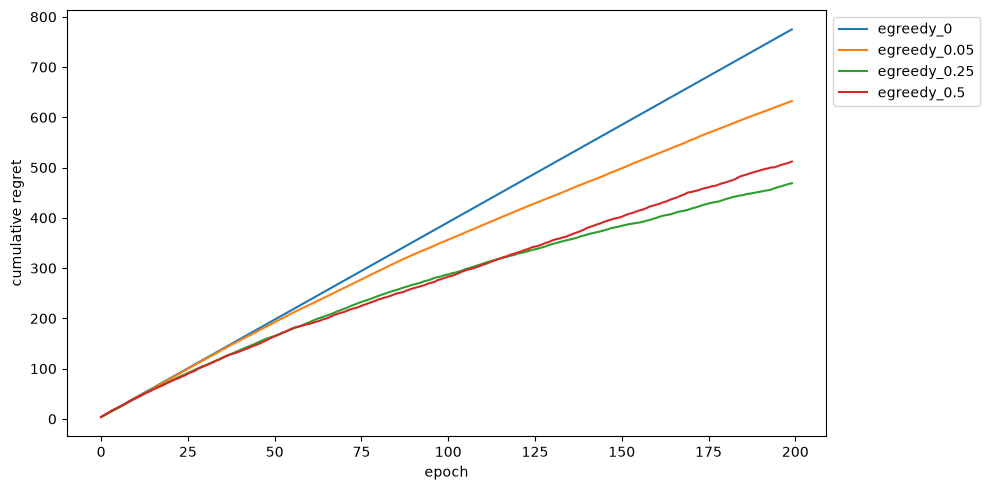

In [15]:
runner.plot_results(results, mode='regret')

In [16]:
# mozemy sprawdzic, jaka wiedze bandyta zdobyl o poszczegolnych ramionach

trained = next(bandit for bandit in bandits if bandit.bandit_id == 'egreedy_0.25')
top_arms = sorted(arm_ids, key=lambda arm_id: trained.stats[arm_id].mean, reverse=True)[:recommendation_size]

print(f"{'arm':<12}{'trials':>8}{'successes':>11}{'mean':>7}{'true CTR':>10}")
for arm_id in top_arms:
    stats = trained.stats[arm_id]
    print(f'{arm_id:<12}{stats.trials:>8}{stats.successes:>11}{stats.mean:>7.2f}{arms[arm_id].click_probability:>10.2f}')

arm           trials  successes   mean  true CTR
top_0             50         37   0.74      0.63
top_4            116         77   0.66      0.65
top_2             85         43   0.51      0.56
good_3            18          9   0.50      0.38
good_0            61         28   0.46      0.44
average_44        20          9   0.45      0.27
good_9            84         34   0.40      0.43
good_12          133         52   0.39      0.42
average_33       160         57   0.36      0.29
average_0         43         14   0.33      0.26


## Część 3. - UCB (Upper Confidence Bound)

In [17]:
class UCB(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], optimism_weight: float):
        super().__init__(bandit_id, arm_ids)
        self.optimism_weight = optimism_weight
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def calculate_total_trials(self):
        return sum(map(lambda stat: self.stats[stat].trials, self.stats))

    def optimism(self, arm_id: str) -> float:
        if self.stats[arm_id].trials == 0:
            return inf
        return self.optimism_weight * sqrt(2 * log(self.calculate_total_trials()) / self.stats[arm_id].trials)

    def recommend(self, size: int) -> List[str]:
        recommendation_probabilities = list(
            map(
                lambda arm_id: (self.stats[arm_id].mean + self.optimism(arm_id), arm_id),
                self.arm_ids
            )
        )

        recommendation_probabilities.sort(key=lambda x: x[0], reverse=True)

        return [arm_id for _, arm_id in recommendation_probabilities[:size]]

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [18]:
bandits = [UCB(f'ucb_{optimism_weight}', arm_ids, optimism_weight) for optimism_weight in [0.01, 0.1, 0.3, 1]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ucb_0.01
Simulating: ucb_0.1
Simulating: ucb_0.3
Simulating: ucb_1

bandit                 total reward   total regret
ucb_0.01                        828          201.3
ucb_0.1                         752          266.5
ucb_0.3                         593          415.6
ucb_1                           315          694.9


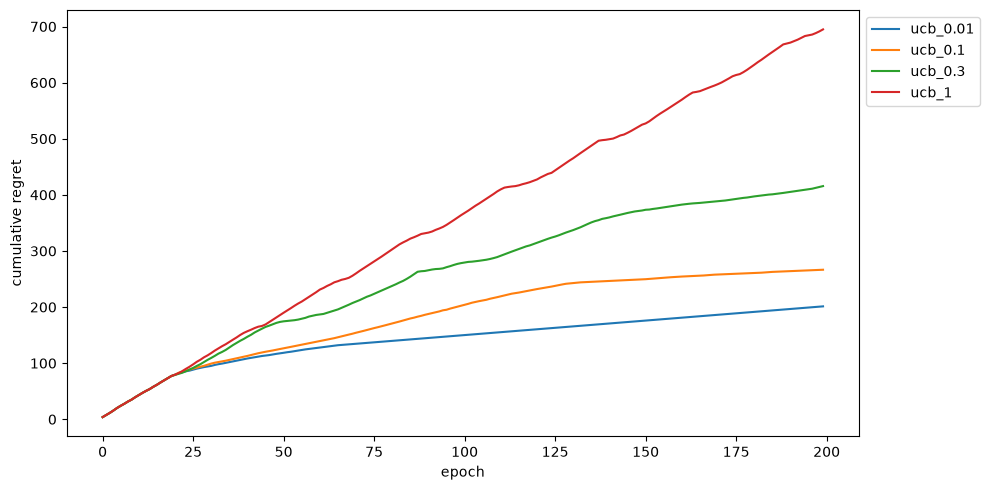

In [19]:
runner.plot_results(results, mode='regret')

## Część 4. - Thompson Sampling

In [20]:
@dataclass
class DistributionParams:
    alpha: float
    beta: float

In [21]:
class ThompsonSampling(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], reward_multiplier: float, regret_multiplier: float):
        super().__init__(bandit_id, arm_ids)
        self.reward_multiplier = reward_multiplier
        self.regret_multiplier = regret_multiplier
        self.arms_params = {arm_id: DistributionParams(1, 1) for arm_id in arm_ids}

    def recommend(self, size: int) -> List[str]:
        random_probabilities = []
        for arm_id in self.arm_ids:
            probability = betavariate(self.arms_params[arm_id].alpha, self.arms_params[arm_id].beta)
            random_probabilities.append((probability, arm_id))

        random_probabilities.sort(key=lambda x: x[0], reverse=True)

        return [arm_id for _, arm_id in random_probabilities[:size]]

    def feedback(self, arm_id: str, reward: int) -> None:
        if reward == 0:
            self.arms_params[arm_id].beta += self.regret_multiplier
        else:
            self.arms_params[arm_id].alpha += self.reward_multiplier


In [22]:
bandits = [ThompsonSampling(f'ts_{reward_multiplier}_{regret_multiplier}', arm_ids, reward_multiplier, regret_multiplier)
           for reward_multiplier, regret_multiplier in [(1, 1), (10, 10), (1, 10), (10, 1)]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: ts_1_1
Simulating: ts_10_10
Simulating: ts_1_10
Simulating: ts_10_1

bandit                 total reward   total regret
ts_10_1                         716          310.3
ts_10_10                        606          401.6
ts_1_1                          536          490.8
ts_1_10                         440          568.8


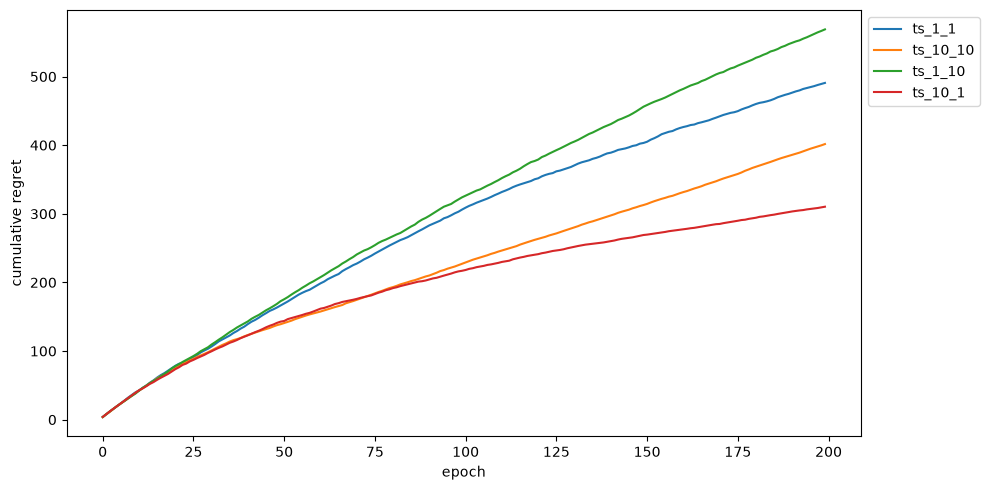

In [23]:
runner.plot_results(results, mode='regret')

## Część 5. - Własny bandyta

Zaimplementuj własny algorytm bandyty. Może to być np. bandyta Softmax, Thompson Sampling z dwoma rozkładami beta, Thompson Sampling z rozkładem innnym niż beta lub cokolwiek innego, co ci przyjdzie do głowy.

### Softmax

Bandyta Softmax opiera się na wzorze:

$$
P(i) = \frac{e^{\frac{mean_i}{\tau}}}{\sum_{j=1}^{n} e^{\frac{mean_j}{\tau}}}
$$

gdzie $\tau$ to temperatura.

Zamiast osobno eksploatować najlepsze ramię i eksplorować losowo (jak $\varepsilon$-greedy), Softmax łączy obie fazy: każde ramię dostaje szansę wyboru proporcjonalną do empirycznego CTR ($mean_i$). Ramiona z wyższą średnią są wybierane częściej, ale słabsze wciąż mają $P(i) > 0$.

Parametr $\tau$ steruje stopniem losowości:
- małe $\tau$ → rozkład ostrzejszy, prawie greedy (eksploatacja),
- duże $\tau$ → rozkład bliższy jednostajnemu (eksploracja).

Działa to w ten sposób, że normalizujemy prawdopodobieństwa wygranej każdego z ramion przy pomocy funkcji softmax, dzięki czemu dostajemy wartości, które sumują się do 1. Możemy wówczas dokonać losowania uwzględniającego wagi każdego z ramion. Dotakowo, ponieważ wymagamy kilku produktów do rekomendowania, wykonujemy losowanie bez zwracania, gdzie usuwamy już wylosowane produkty z puli dostępnych i na tej nowej puli ponownie przeliczamy softmax oraz dokonujemy losowania według wag. 

In [24]:
from math import exp

In [ ]:
class Softmax(Bandit):
    def __init__(self, bandit_id: str, arm_ids: List[str], tau: float):
        super().__init__(bandit_id, arm_ids)
        self.tau = tau
        self.stats = {arm_id: ArmStats() for arm_id in arm_ids}

    def softmax_probs(self, arm_ids: List[str]) -> List[float]:
        values = [self.stats[arm_id].mean for arm_id in arm_ids]
        max_value = max(values) # softmax trick to avoid overflow
        weights = [exp((value - max_value) / self.tau) for value in values]
        total = sum(weights)
        return [weight / total for weight in weights]

    def categorical_draw(self, probs: List[float]) -> int:
        z = random()
        cum_prob = 0.0
        for i, prob in enumerate(probs):
            cum_prob += prob
            if cum_prob > z:
                return i
        return len(probs) - 1

    def recommend(self, size: int) -> List[str]:
        remaining = list(self.arm_ids)
        recommended = []
        for _ in range(size):
            probs = self.softmax_probs(remaining)
            idx = self.categorical_draw(probs)
            recommended.append(remaining.pop(idx))
        return recommended

    def feedback(self, arm_id: str, reward: int) -> None:
        self.stats[arm_id].update(reward)

In [26]:
bandits = [Softmax(f'softmax_{tau}', arm_ids, tau) for tau in [0.1, 0.2, 0.3, 0.4, 0.5]]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: softmax_0.1
Simulating: softmax_0.2
Simulating: softmax_0.3
Simulating: softmax_0.4
Simulating: softmax_0.5

bandit                 total reward   total regret
softmax_0.1                     569          435.6
softmax_0.2                     478          549.5
softmax_0.3                     431          605.6
softmax_0.4                     340          689.7
softmax_0.5                     337          693.5


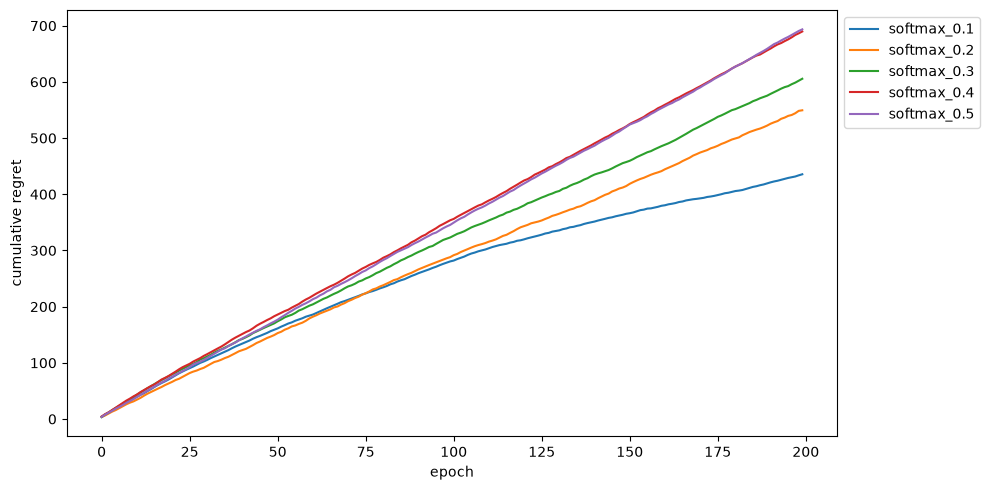

In [27]:
runner.plot_results(results, mode='regret')

## Część 6. - porównanie bandytów

In [28]:
# tworzymy nowych bandytow na potrzeby porowwnania
# mozesz wykorzystac parametry znalezione na wczesniejszych etapach lub przetestowac nowe
bandits = [
    Random('random', arm_ids),
    Oracle('oracle', arm_ids, arms),
    EGreedy('egreedy', arm_ids, epsilon=0.1),
    UCB('ucb', arm_ids, optimism_weight=1),
    ThompsonSampling('ts', arm_ids, reward_multiplier=1, regret_multiplier=1),
    Softmax('softmax', arm_ids, tau=0.1),
]

runner = Runner(arms, bandits)
results = runner.simulate(epochs, recommendation_size)
runner.print_summary(results)

Simulating: random
Simulating: oracle
Simulating: egreedy
Simulating: ucb
Simulating: ts
Simulating: softmax

bandit                 total reward   total regret
oracle                         1015            0.0
softmax                         624          401.4
egreedy                         596          447.4
ts                              485          535.8
ucb                             320          694.1
random                          257          764.2


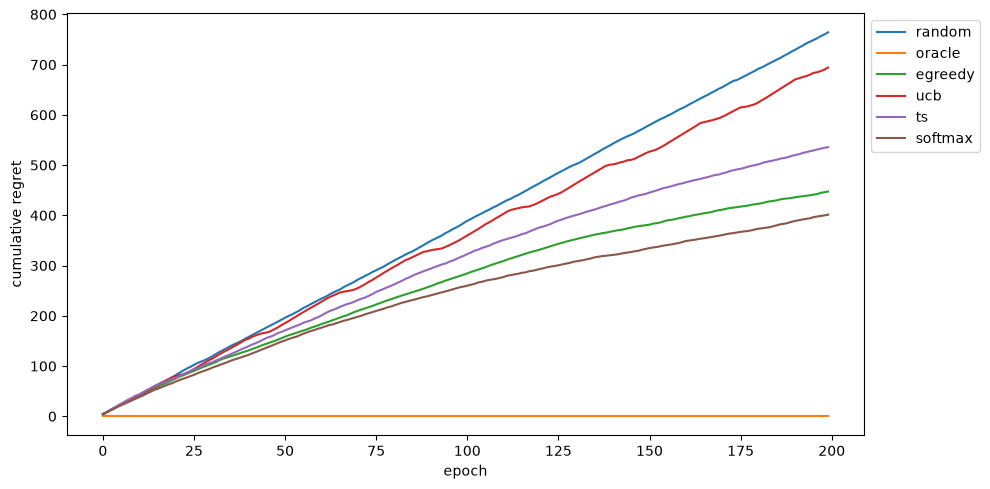

In [29]:
runner.plot_results(results, mode='regret')

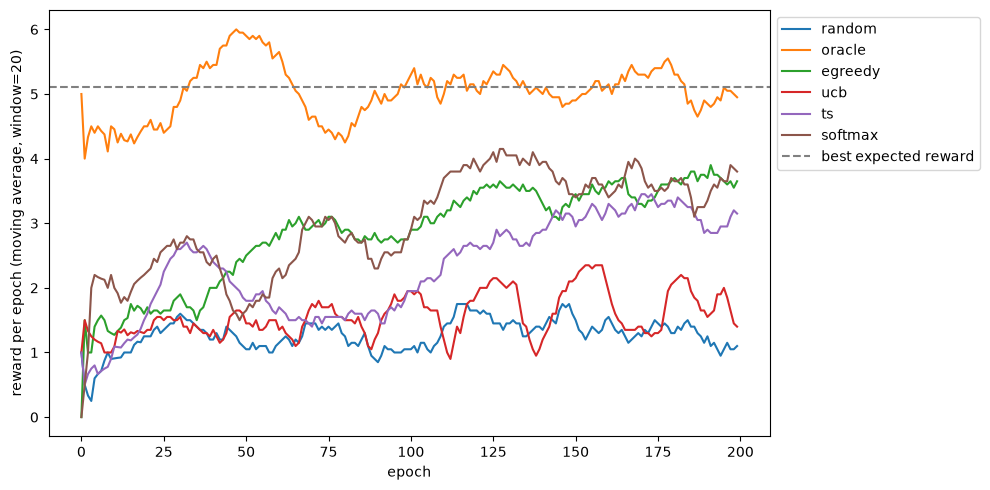

In [30]:
runner.plot_results(results, mode='reward')